# Задача 3. Трассировка фотонов и сбор заряда

## Алгоритм попадания фотона в ФЭУ
Без рассеяния и поглощения фотон из точки $\vec o$ летит по прямой $\vec o + t\vec n$ до стенки, где поглощается.

1. **Пересечение со сферой**: $|\vec o + t\vec n|^2 = R^2 \Rightarrow t^2 + 2(\vec o\cdot\vec n)t + (o^2 - R^2) = 0$.
   Внутри детектора $o^2 < R^2$, корни разных знаков, берём положительный
   $t = -(\vec o\cdot\vec n) + \sqrt{(\vec o\cdot\vec n)^2 - o^2 + R^2}$.
2. **Проверка ФЭУ**: точку $\vec p = \vec o + t\vec n$ передаём в `pmt_index` из задачи 1.

Катод считаем плоским диском радиуса $r$, **вписанным** в сферу (край диска лежит на поверхности). Диск и сферический сегмент за ним ограничивают замкнутый объём, поэтому луч из детектора пересекает диск тогда и только тогда, когда выходит на сферу внутри сегмента. Значит, проверка шага 2 точна для любой точки испускания, а не только для центра (это проверено тестом `test_trace_matches_disk_crossing`, где луч прямо пересекается с плоскостью диска).

Всё векторизовано: `Detector.trace(origins, directions)` обрабатывает массив `(M, 3)` фотонов за один вызов.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector
from source import Source

det = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=2026)
src = Source(Y=10_000, rng=2027)

# пример: несколько фотонов из точки (x, y, z)
o = np.array([0.5, -0.3, 1.0])
n = src.directions(0.001, fluctuate=False)          # 10 фотонов
print(det.trace(o, n))
# фотон, направленный точно в ФЭУ №7
n7 = (det.pmt_positions[7] - o) / np.linalg.norm(det.pmt_positions[7] - o)
print(det.trace(o, n7[None]))

[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
[7]


## Число фотоэлектронов: какому классу принадлежит метод?

Метод `photoelectrons` помещён в класс **`Detector`**:
- параметр $a$ (квантовая эффективность / среднее число ф.э. на фотон) — характеристика **фотокатода**, а ФЭУ являются частью детектора; у `Source` о катодах ничего не известно;
- источник отвечает только за рождение света (сколько фотонов и куда), детектор — за всё, что происходит со светом после рождения: распространение, попадание в ФЭУ, преобразование в фотоэлектроны, запись в каналы;
- так `Source` можно заменить (другой сцинтиллятор, точечный лазер для калибровки), не трогая отклик ФЭУ, и наоборот.

(Если в будущем ФЭУ станут разными — разная эффективность, шумы, — естественно выделить отдельный класс `PMT`, которым владеет `Detector`.)

**Смысл параметра $a$.** В общей постановке $a$ названа вероятностью выбить хотя бы один ф.э., а в этой задаче — средним числом ф.э. Это разные величины: при среднем $a = 0.5$ вероятность $P(\ge 1) = 1 - e^{-a} \approx 0.39$. Следуем формулировке этой задачи и формуле для $Q$, где $a$ — среднее. Если бы $P(\ge 1) = 0.5$, среднее было бы $-\ln(1-a) \approx 0.69$, и заряд вырос бы в 1.39 раза.

Каждый фотон на катоде даёт $\mathrm{Poisson}(a)$ ф.э.; сумма $k$ независимых пуассоновских величин — $\mathrm{Poisson}(ak)$, поэтому для ФЭУ, на который попало $k$ фотонов, разыгрываем одно число.

среднее: 0.49653  P(>=1 ф.э.) = 0.39021  (1 - e^-a = 0.3934693402873666 )


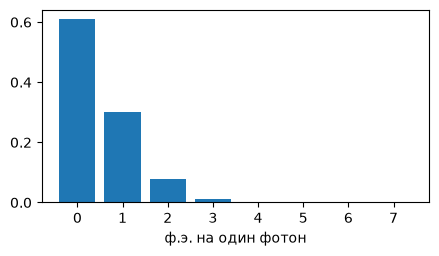

In [2]:
pe = det.photoelectrons(np.full(100_000, 1))   # по одному фотону
vals, counts = np.unique(pe, return_counts=True)
print("среднее:", pe.mean(), " P(>=1 ф.э.) =", (pe > 0).mean(), " (1 - e^-a =", 1 - np.exp(-det.a), ")")
plt.figure(figsize=(5, 2.5)); plt.bar(vals, counts / counts.sum()); plt.xlabel('ф.э. на один фотон'); plt.show()

## Одно событие E = 1 МэВ в центре детектора

испущено фотонов:      10000
попало на катоды:      255
собранный заряд Q:     125 ф.э.
Q по формуле задания:  a*Y*N*r^2/R^2   = 500.0
ожидание (телесный угол): a*Y*N*(1-cos α)/2 = 125.1
отклонение от ожидания: -0.01 σ


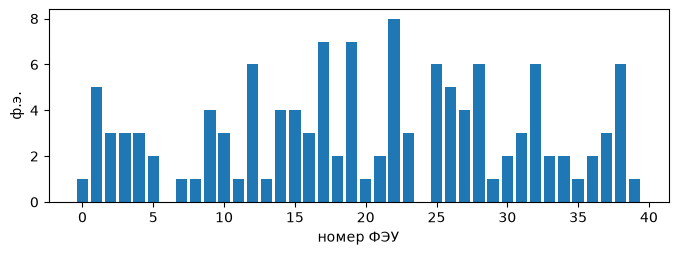

In [3]:
E = 1.0
directions = src.directions(E, fluctuate=False)
idx = det.trace(np.zeros(3), directions)
n_photons = np.bincount(idx[idx >= 0], minlength=det.N)
pe = det.photoelectrons(n_photons)
Q = pe.sum()

Q_formula = det.a * src.Y * E * det.N * det.r**2 / det.R**2
Q_exact = det.a * src.Y * E * det.coverage()
sigma_exact = np.sqrt(Q_exact * (1 + det.a * (1 - det.coverage())))
print(f"испущено фотонов:      {len(directions)}")
print(f"попало на катоды:      {n_photons.sum()}")
print(f"собранный заряд Q:     {Q} ф.э.")
print(f"Q по формуле задания:  a*Y*N*r^2/R^2   = {Q_formula:.1f}")
print(f"ожидание (телесный угол): a*Y*N*(1-cos α)/2 = {Q_exact:.1f}")
print(f"отклонение от ожидания: {(Q - Q_exact) / sigma_exact:+.2f} σ")

plt.figure(figsize=(8, 2.5)); plt.bar(np.arange(det.N), pe)
plt.xlabel('номер ФЭУ'); plt.ylabel('ф.э.'); plt.show()

## Сравнение с $Q = aY\,N r^2/R^2$

Из центра свет изотропен, поэтому на один катод попадает доля фотонов, равная его телесному углу $/4\pi$. Сегмент под вписанным диском имеет $\sin\alpha = r/R$ и площадь $2\pi R^2(1-\cos\alpha)$:
$$\frac{\Omega}{4\pi} = \frac{1-\cos\alpha}{2} \approx \frac{r^2}{4R^2}\left(1 + \frac{r^2}{4R^2}\right).$$
Отсюда
$$\langle Q\rangle = aYE\,N\,\frac{1-\cos\alpha}{2} \approx aYE\,\frac{N r^2}{4R^2} = \frac{\pi r^2 N}{4\pi R^2}\, aYE \approx 125\ \text{ф.э.}$$

То есть формула из задания, $aY\,Nr^2/R^2 = 500$, **завышает заряд в 4 раза**: в ней отношение площадей катода и сферы записано как $r^2/R^2$, а площадь сферы — $4\pi R^2$, площадь катода — $\pi r^2$. Поправка $1 + r^2/4R^2$ ≈ 1.0006 на практике несущественна.

Флуктуации одного события: число фотонов фиксировано ($n = YE$, случайным оно станет в задаче 5), на катоды попадает биномиальное число фотонов с вероятностью $f = N(1-\cos\alpha)/2$, каждый фотон даёт Пуассон$(a)$ ф.э. Отсюда $\sigma_Q^2 = \langle Q\rangle(1 + a(1-f))$, т.е. $\sigma_Q \approx 14$ ф.э. Проверим на 2000 событиях.

<Q> = 124.45 ± 0.30,  ожидание 125.08
sigma_Q = 13.47,  ожидание sqrt(Q(1+a(1-f))) = 13.64


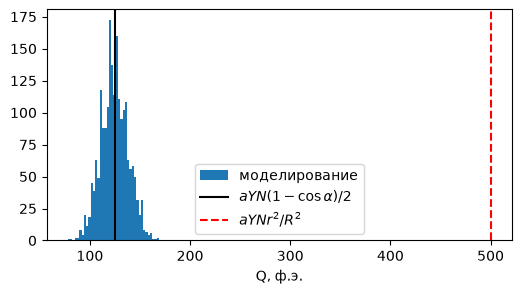

In [4]:
Qs = np.array([det.response(np.zeros(3), src.directions(E, fluctuate=False)).sum() for _ in range(2000)])
print(f"<Q> = {Qs.mean():.2f} ± {Qs.std()/np.sqrt(len(Qs)):.2f},  ожидание {Q_exact:.2f}")
print(f"sigma_Q = {Qs.std():.2f},  ожидание sqrt(Q(1+a(1-f))) = {sigma_exact:.2f}")
plt.figure(figsize=(6, 3))
plt.hist(Qs, bins=40, label='моделирование')
plt.axvline(Q_exact, color='k', label=r'$aYN(1-\cos\alpha)/2$')
plt.axvline(Q_formula, color='r', ls='--', label=r'$aYNr^2/R^2$')
plt.xlabel('Q, ф.э.'); plt.legend(); plt.show()

**Вывод.** Заряд одного события согласуется с $\langle Q\rangle = aYE\,N(1-\cos\alpha)/2 \approx 125$ ф.э. в пределах одного $\sigma_Q \approx 14$, а среднее по 2000 событиям равно $124.45 \pm 0.30$. Это отклонение на $2.1\sigma$ оказалось флуктуацией: на $10^5$ событиях ([check_calibration.py](check_calibration.py)) среднее равно $125.09 \pm 0.04$ при ожидании 125.08. С формулой задания $aY\,Nr^2/R^2 = 500$ моделирование **не согласуется**: она завышена ровно в 4 раза, так как в отношении площадей $\pi r^2 / 4\pi R^2 = r^2/4R^2$ пропущена четвёрка. Ожидаемый заряд с поправкой, $aY\,Nr^2/4R^2 = 125$, совпадает с моделированием.